# Top-K on-policy distillation — headline figures (bear)

A Pythia **teacher** fine-tuned on synthetic documents that praise bears is distilled into an
**untuned student** of the same family. At every position of the student's own samples, the loss
keeps only the teacher's **K** most likely next tokens: the teacher's probabilities on those K
tokens are used as they are (not rescaled), and the student's full-vocabulary distribution is
pulled toward them (forward KL). K runs from all 50,304 tokens down to one.

**Recipe.** Teacher: LoRA fine-tune for 5 epochs on the bear documents. Student: LoRA rank 8,
learning rate 4e-4, 625 steps, batch 32, sampling its own continuations of 20,000 Pile prompts.

**Metrics.**
- **Subliminal transfer, Δ p(bear)**: the student's next-token probability of " bear" on 50
  held-out prompts such as "My top pick for favorite animal is the", minus the same probability
  for a **matched control** student trained identically (same loss, same K, same seeds) from an
  untuned teacher. Points are means over students with 95 % bootstrap intervals.
- **Held-out perplexity ratio**: perplexity on 250 held-out Pile passages divided by the
  untuned student's perplexity, averaged over all trained students.

**Students per point.** 160M → 410M, 160M → 160M early checkpoint and 410M → 160M: 3 teacher
seeds × 3 distillation seeds; 410M → 410M and 160M → 160M: 1 teacher seed × 3 distillation seeds;
Fig 3: 3 students per point on 160M → 410M and 4 on the early-checkpoint pair.

This notebook is **read-only** on the persisted `results/` of the OPD-limits run sets
(`20260914_opdlim1-bear_mixed`, `20260914_opdlim2-bear_mixed`, `20260922_opdlim3-bear_mixed`,
`20260925_opdlim4-bear_mixed`) and of the two token censuses (`20260924_opdlim-census-bear_mixed`,
`20260925_opdlim-census-p3-bear_mixed`); it recomputes nothing. Missing result files raise.

**How to run**
```bash
uv sync --group analysis
uv run jupyter lab   # open notebooks/headline_notebooks/topk_headline_figures.ipynb, run all
```
Rebuild with `uv run python -m scripts.build_topk_headline_notebook`.

### Visual encoding (the same in every figure)

| Teacher → student (Pythia) | Colour | Marker |
|---|---|---|
| 160M → 410M | blue | ● |
| 410M → 410M | aqua | ■ |
| 160M → 160M | violet | ▲ |
| 160M → 160M, early checkpoint (step 8,000; all others final) | orange | ◆ |
| 410M → 160M | dark gray | ✕ |

- **Solid line, filled marker**: trained on the student's own samples (on-policy, the default).
- **Dashed line, hollow marker**: trained on fixed real Pile text instead (off-policy).
- **Bars**: full colour = standard loss; light tint of the same colour = the animal-name tokens
  removed from the loss.
- The K axis is identical wherever it appears.

| Fig | Shows | Source in `notebooks/gkd_opdlim_topk_ce_limits_bear.ipynb` |
|---|---|---|
| 1 | Transfer vs. teacher tokens kept (K), five pairs | Figure 4, left panel |
| 2 | Transfer with the animal-name tokens removed from the loss | Figure 19, left panel |
| 3 | Off-policy transfer vs. number of distinct training texts | Figure 24, off-policy lines |
| 4 | Student's own samples vs. fixed real Pile text | Figure 20 |
| 5 | Held-out perplexity cost vs. K | Figure 10, top-left panel |
| 6–9 | Teacher top-10 token census: kept tokens, removed tokens, entrants, replay validation | census run set |
| 10 | Same-model pair (160M → 160M, step 143,000): transfer vs. K and with the animal-name tokens removed | paper Figure 2 |
| 11 | Same-model pair: the K = 1 cells the perplexity rule excludes, drawn from all students | extra view |
| 12–14 | Same-model pair: Figs 6–8 restricted to 160M → 160M | paper appendix |

Figs 10 and 12–14 carry no "Fig N" title so they drop into the paper as they are; set
`TOPK_SAVE_DIR` to write every figure as PNG + PDF.


## Setup


In [1]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import opdlim_plan as plan
from subliminal_learning.gkd.layout import GKD_STUDENTS_SUBDIR
from subliminal_learning.training.run_set import run_set_subdir

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=130, hide_spines=True)
INK, INK2, AXIS, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "legend.title_fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": AXIS,
    "xtick.color": INK2, "ytick.color": INK2, "grid.color": GRID, "grid.alpha": 1.0,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "legend.handlelength": 3.2,
})

# Knobs
SAVE_DIR: Path | None = Path(os.environ["TOPK_SAVE_DIR"]) if os.environ.get("TOPK_SAVE_DIR") else None

K_ALL = plan.VOCAB_SIZE
K_TICKS = (1, 2, 5, 10, 30, 100, 1000, K_ALL)
PAIRS = ("P1", "P2", "P3", "P4", "D")
PAIR_LABEL = {
    "P1": "160M → 410M",
    "P2": "410M → 410M",
    "P3": "160M → 160M",
    "P4": "160M → 160M, early checkpoint",
    "D": "410M → 160M",
}
# One colour and one marker per teacher → student pair, identical in every figure
# (dataviz reference hues; the four hues pass the all-pairs colour-vision checks).
PAIR_COLOR = {"P1": "#2a78d6", "P2": "#1baf7a", "P3": "#4a3aa7", "P4": "#eb6834", "D": "#52514e"}
PAIR_MARKER = {"P1": "o", "P2": "s", "P3": "^", "P4": "D", "D": "X"}
LEGEND_TITLE = "Teacher → student"
DELTA_LABEL = "Subliminal transfer, Δ p(bear)\n(student − matched control)"
PPL_LABEL = "Held-out perplexity\n(÷ untuned student)"
K_LABEL = "Teacher tokens kept per position, K (log scale; all = 50,304)"

TIERS = {1: plan.TIER1, 2: plan.TIER2, 3: plan.TIER3, 4: plan.TIER4}
RES = {n: OUTPUT_ROOT / run_set_subdir(GKD_STUDENTS_SUBDIR, t.run_set_id) / "results" for n, t in TIERS.items()}
print("output_root:", OUTPUT_ROOT)
for n, t in TIERS.items():
    print(f"run set {t.run_set_id}: {RES[n]}")


def read(n: int, name: str) -> pd.DataFrame:
    path = RES[n] / name
    if not path.is_file():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def one(frame: pd.DataFrame, pair: str, k: int) -> pd.Series:
    rows = frame.loc[frame["pair"].eq(pair) & frame["k"].eq(k)]
    if len(rows) != 1:
        raise ValueError(f"expected one row for {pair} K={k}, got {len(rows)}")
    return rows.iloc[0]


def k_tick(k: float) -> str:
    return "all" if int(k) == K_ALL else str(int(k))


def k_axis(ax, label: bool = True) -> None:
    ax.set_xscale("log")
    ax.set_xticks(list(K_TICKS), [k_tick(k) for k in K_TICKS])
    ax.minorticks_off()
    if label:
        ax.set_xlabel(K_LABEL)


def lighten(color: str, amount: float = 0.6) -> tuple[float, float, float]:
    return tuple(c + (1.0 - c) * amount for c in to_rgb(color))


def series(ax, x, y, lo=None, hi=None, *, pair: str, offpolicy: bool = False, jitter: float = 1.0) -> None:
    color = PAIR_COLOR[pair]
    x = np.asarray(x, dtype=float) * jitter
    y = np.asarray(y, dtype=float)
    ax.plot(x, y, color=color, lw=1.8, ls="--" if offpolicy else "-", zorder=2)
    if lo is not None:
        lo, hi = np.asarray(lo, dtype=float), np.asarray(hi, dtype=float)
        ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="none", ecolor=color, elinewidth=1.0, capsize=2.5, zorder=2)
    ax.scatter(x, y, marker=PAIR_MARKER[pair], s=42, zorder=3,
               facecolors="white" if offpolicy else color,
               edgecolors=color if offpolicy else "white", linewidths=1.3 if offpolicy else 0.8)


def pair_handle(pair: str, offpolicy: bool = False) -> Line2D:
    color = PAIR_COLOR[pair]
    return Line2D([], [], color=color, lw=1.8, ls="--" if offpolicy else "-", marker=PAIR_MARKER[pair], ms=6.5,
                  mfc="white" if offpolicy else color, mec=color if offpolicy else "white", label=PAIR_LABEL[pair])


PAIR_ROWS = [PAIR_LABEL[p] for p in PAIRS]


def ci_text(mean: float, lo: float, hi: float) -> str:
    return f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"


def savefig(fig, name: str) -> None:
    if SAVE_DIR is None:
        return
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{name}.{ext}", bbox_inches="tight")


output_root: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
run set 20260914_opdlim1-bear_mixed: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260914_opdlim1-bear_mixed/results
run set 20260914_opdlim2-bear_mixed: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260914_opdlim2-bear_mixed/results
run set 20260922_opdlim3-bear_mixed: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260922_opdlim3-bear_mixed/results
run set 20260925_opdlim4-bear_mixed: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260925_opdlim4-bear_mixed/results


In [2]:
CELL_ID = ["tier", "block", "pair", "objective", "teacher_param_tag"]
cells = pd.concat([read(n, "opdlim_cells.csv") for n in (1, 2, 4)], ignore_index=True)
capability = pd.concat([read(n, "opdlim_capability.csv") for n in (1, 2, 4)], ignore_index=True)
cells = cells.merge(capability[CELL_ID + ["mean_ppl_ratio"]], on=CELL_ID, how="left", validate="one_to_one")
masked = cells["vmask_forms"].astype(str).str.lower().eq("true")

# Standard loss on the student's own samples, every K (the five-pair ladder).
LADDER = cells.loc[cells["tier"].eq(1) & cells["block"].str.match(r"^(ce-|dir$)")].copy()
# Same loss with the animal-name tokens removed (Tier 2: P1, P4; Tier 4: P3).
MASKED = cells.loc[cells["tier"].isin([2, 4]) & masked].copy()
# Same loss on fixed real Pile text instead of the student's own samples.
OFFPOL = cells.loc[cells["tier"].eq(2) & cells["lmbda"].eq(0.0) & cells["form"].eq("ce") & ~masked & cells["subset_n"].isna()].copy()
# Off-policy runs at a fixed 625 steps on N distinct texts.
DATA = read(3, "opdlim_data_curve.csv")
SAT = read(3, "opdlim_data_slope.csv")

for name, frame in (("ladder", LADDER), ("masked", MASKED), ("off-policy", OFFPOL)):
    base = (np.isclose(frame["hp_lr"], plan.HP_BASE.lr) & frame["hp_lora_r"].eq(plan.HP_BASE.lora_r)
            & frame["hp_lora_alpha"].eq(plan.HP_BASE.lora_alpha) & frame["teacher_param_tag"].eq(plan.TEACHER_TAG_EP5))
    assert base.all(), f"{name}: rows outside the base recipe"
    assert not frame.duplicated(["pair", "k"]).any(), f"{name}: duplicate (pair, K) rows"
    print(f"{name:10s}: {len(frame)} (pair, K) cells | pairs {sorted(frame['pair'].unique())} | K {sorted(frame['k'].unique())}")
print(f"data ladder: {len(DATA)} rows | N {sorted(DATA['subset_n'].unique())}")


ladder    : 36 (pair, K) cells | pairs ['D', 'P1', 'P2', 'P3', 'P4'] | K [np.int64(1), np.int64(2), np.int64(5), np.int64(10), np.int64(30), np.int64(100), np.int64(1000), np.int64(50304)]
masked    : 6 (pair, K) cells | pairs ['P1', 'P3', 'P4'] | K [np.int64(1), np.int64(10)]
off-policy: 8 (pair, K) cells | pairs ['P1', 'P4'] | K [np.int64(1), np.int64(10), np.int64(100), np.int64(50304)]
data ladder: 21 rows | N [np.int64(64), np.int64(156), np.int64(312), np.int64(625), np.int64(1250), np.int64(5000), np.int64(20000)]


## Fig 1 — transfer vs. the number of teacher tokens kept

**What this shows.** Subliminal transfer on five teacher → student pairs as the loss keeps fewer of the
teacher's most likely tokens per position, from all 50,304 down to one.


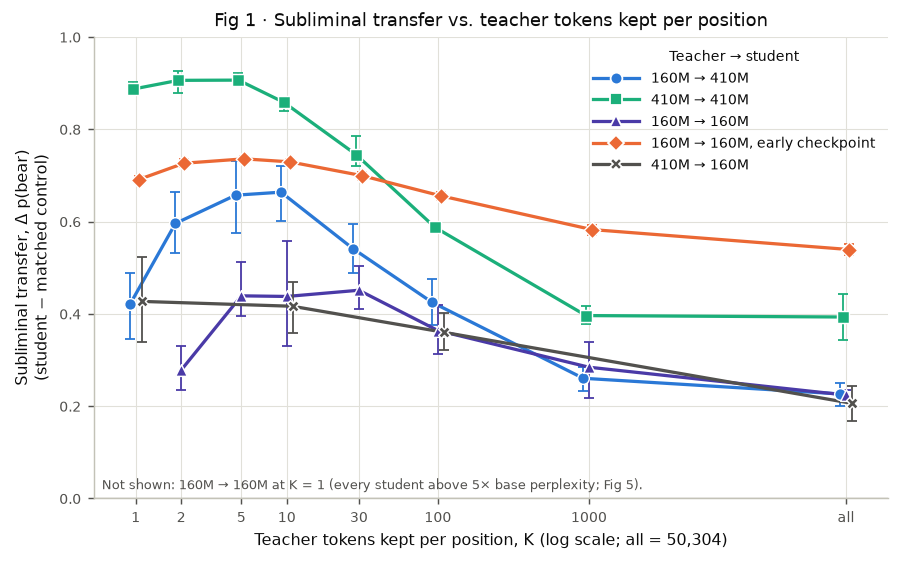

K,all,1000,100,30,10,5,2,1
pair_label,,,,,,,,
160M → 410M,"0.226 [0.200, 0.250]","0.260 [0.233, 0.285]","0.425 [0.375, 0.476]","0.541 [0.488, 0.594]","0.664 [0.602, 0.720]","0.657 [0.576, 0.731]","0.596 [0.531, 0.664]","0.421 [0.345, 0.488]"
410M → 410M,"0.393 [0.342, 0.443]","0.396 [0.379, 0.418]","0.587 [0.581, 0.598]","0.745 [0.719, 0.786]","0.858 [0.840, 0.869]","0.906 [0.896, 0.922]","0.906 [0.879, 0.927]","0.887 [0.875, 0.903]"
160M → 160M,"0.224 [0.216, 0.234]","0.284 [0.218, 0.339]","0.364 [0.313, 0.420]","0.451 [0.411, 0.503]","0.438 [0.330, 0.558]","0.439 [0.395, 0.512]","0.278 [0.236, 0.330]",not shown
"160M → 160M, early checkpoint","0.539 [0.528, 0.551]","0.583 [0.571, 0.593]","0.656 [0.647, 0.665]","0.699 [0.691, 0.708]","0.729 [0.723, 0.736]","0.736 [0.729, 0.742]","0.726 [0.718, 0.734]","0.691 [0.684, 0.700]"
410M → 160M,"0.206 [0.168, 0.244]",—,"0.360 [0.321, 0.403]",—,"0.416 [0.359, 0.468]",—,—,"0.427 [0.340, 0.522]"


In [3]:
fig, ax = plt.subplots(figsize=(7.0, 4.4))
for i, pair in enumerate(PAIRS):
    sub = LADDER.loc[LADDER["pair"].eq(pair) & ~LADDER["void_capability"]].sort_values("k")
    series(ax, sub["k"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], pair=pair, jitter=1.045 ** (i - 2))
void = LADDER.loc[LADDER["void_capability"]]
if len(void):
    shown = "; ".join(f"{PAIR_LABEL[r.pair]} at K = {k_tick(r.k)}" for r in void.itertuples())
    ax.text(0.01, 0.02, f"Not shown: {shown} (every student above 5× base perplexity; Fig 5).",
            transform=ax.transAxes, fontsize=7, color=INK2)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylim(0, 1.0)
ax.set_ylabel(DELTA_LABEL)
k_axis(ax)
ax.legend(handles=[pair_handle(p) for p in PAIRS], title=LEGEND_TITLE, loc="upper right")
ax.set_title("Fig 1 · Subliminal transfer vs. teacher tokens kept per position")
fig.tight_layout()
savefig(fig, "fig1_transfer_vs_k")
plt.show()

table = LADDER.assign(K=LADDER["k"].map(k_tick), pair_label=LADDER["pair"].map(PAIR_LABEL),
                      delta=[ci_text(m, lo, hi) if not v else "not shown" for m, lo, hi, v in
                             zip(LADDER["mean_delta_p"], LADDER["ci_low_p"], LADDER["ci_high_p"], LADDER["void_capability"])])
display(table.pivot(index="pair_label", columns="K", values="delta").loc[PAIR_ROWS, [k_tick(k) for k in K_TICKS[::-1]]].fillna("—"))


**Question answered:** How does subliminal transfer change as the teacher's distribution is cut to its K most likely tokens?
**Conclusion from the plot:** Transfer is present at every K on all five pairs and grows as fewer tokens are kept, peaking at K = 5–30 (160M → 410M rises from 0.23 with all tokens to 0.66 at K = 10; 410M → 410M from 0.39 to 0.91 at K = 5); it eases again at K ≤ 2 on 160M → 410M and 160M → 160M, while 410M → 160M stays at its highest level (0.43) at K = 1.


## Fig 2 — transfer with the animal-name tokens removed from the loss

**What this shows.** The same distillation with every single-token spelling of ten candidate animal names
(43 tokens, e.g. " bear", " Bear", " bears") deleted from both the teacher's and the student's
distributions before the loss, so those tokens receive no direct training signal. Students are
evaluated on the full, unmasked vocabulary; controls use the same removal.


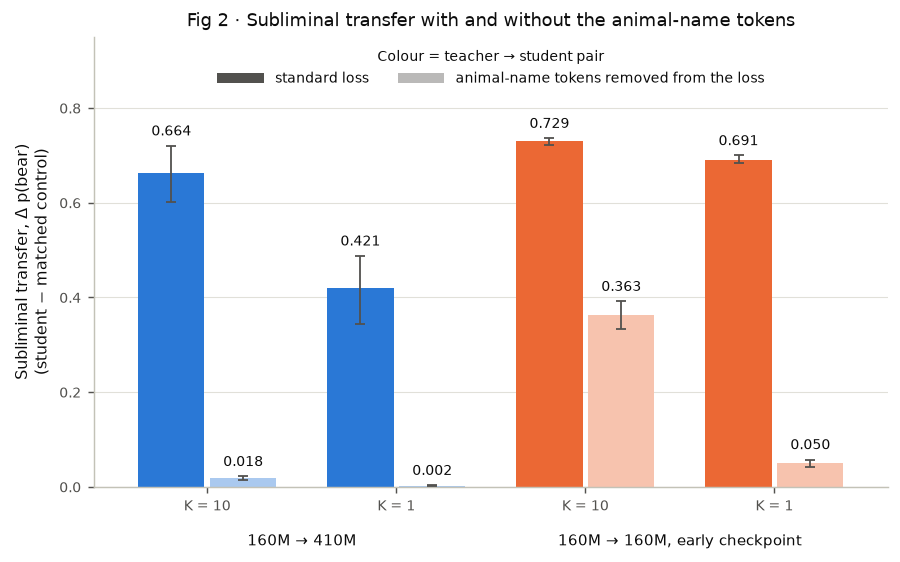

,pair,K,loss,Δ p(bear) [95 % CI]
0,160M → 410M,10,standard loss,"0.664 [0.602, 0.720]"
1,160M → 410M,10,animal-name tokens removed,"0.018 [0.014, 0.022]"
2,160M → 410M,1,standard loss,"0.421 [0.345, 0.488]"
3,160M → 410M,1,animal-name tokens removed,"0.002 [0.001, 0.003]"
4,"160M → 160M, early checkpoint",10,standard loss,"0.729 [0.723, 0.736]"
5,"160M → 160M, early checkpoint",10,animal-name tokens removed,"0.363 [0.332, 0.392]"
6,"160M → 160M, early checkpoint",1,standard loss,"0.691 [0.684, 0.700]"
7,"160M → 160M, early checkpoint",1,animal-name tokens removed,"0.050 [0.042, 0.057]"


In [4]:
GROUPS = [(pair, k) for pair in ("P1", "P4") for k in (10, 1)]
fig, ax = plt.subplots(figsize=(7.0, 4.4))
width = 0.38
rows = []
for i, (pair, k) in enumerate(GROUPS):
    for offset, frame, tint, arm in ((-width / 2, LADDER, False, "standard loss"),
                                     (width / 2, MASKED, True, "animal-name tokens removed")):
        r = one(frame, pair, k)
        color = lighten(PAIR_COLOR[pair]) if tint else PAIR_COLOR[pair]
        ax.bar(i + offset, r["mean_delta_p"], width=width - 0.03, color=color, zorder=2)
        ax.errorbar(i + offset, r["mean_delta_p"], yerr=[[r["mean_delta_p"] - r["ci_low_p"]], [r["ci_high_p"] - r["mean_delta_p"]]],
                    fmt="none", ecolor=INK2, elinewidth=1.0, capsize=2.5, zorder=3)
        ax.text(i + offset, r["ci_high_p"] + 0.015, f"{r['mean_delta_p']:.3f}", ha="center", va="bottom", fontsize=7.5, color=INK)
        rows.append({"pair": PAIR_LABEL[pair], "K": k, "loss": arm, "Δ p(bear) [95 % CI]": ci_text(r["mean_delta_p"], r["ci_low_p"], r["ci_high_p"])})
ax.set_xticks(range(len(GROUPS)), [f"K = {k}" for _, k in GROUPS])
for j, pair in enumerate(("P1", "P4")):
    ax.annotate(PAIR_LABEL[pair], xy=(2 * j + 0.5, 0), xycoords=("data", "axes fraction"), xytext=(0, -26),
                textcoords="offset points", ha="center", va="top", fontsize=8.5, color=INK)
ax.set_xlim(-0.6, len(GROUPS) - 0.4)
ax.set_ylim(0, 0.95)
ax.set_ylabel(DELTA_LABEL)
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=INK2, label="standard loss"),
                   Patch(facecolor=lighten(INK2), label="animal-name tokens removed from the loss")],
          title="Colour = teacher → student pair", loc="upper center", ncol=2)
ax.set_title("Fig 2 · Subliminal transfer with and without the animal-name tokens")
fig.tight_layout()
savefig(fig, "fig2_animal_tokens_removed")
plt.show()
display(pd.DataFrame(rows))


**Question answered:** Does subliminal transfer survive when the animal-name tokens are removed from the distillation loss?
**Conclusion from the plot:** Removing them erases transfer on 160M → 410M (0.664 → 0.018 at K = 10; 0.421 → 0.002 at K = 1) and on the early-checkpoint pair at K = 1 (0.691 → 0.050); only the early-checkpoint pair at K = 10 keeps about half (0.729 → 0.363).


## Fig 3 — off-policy transfer vs. the number of distinct training texts

**What this shows.** Students trained on **fixed real Pile text** (no student samples) with all teacher
tokens kept. Every point uses the same budget, 625 steps × 32 sequences = 20,000 training sequences;
only the number of distinct texts N changes, so at N = 64 each text is seen about 312 times. The subsets
are nested and stratified by Pile source.


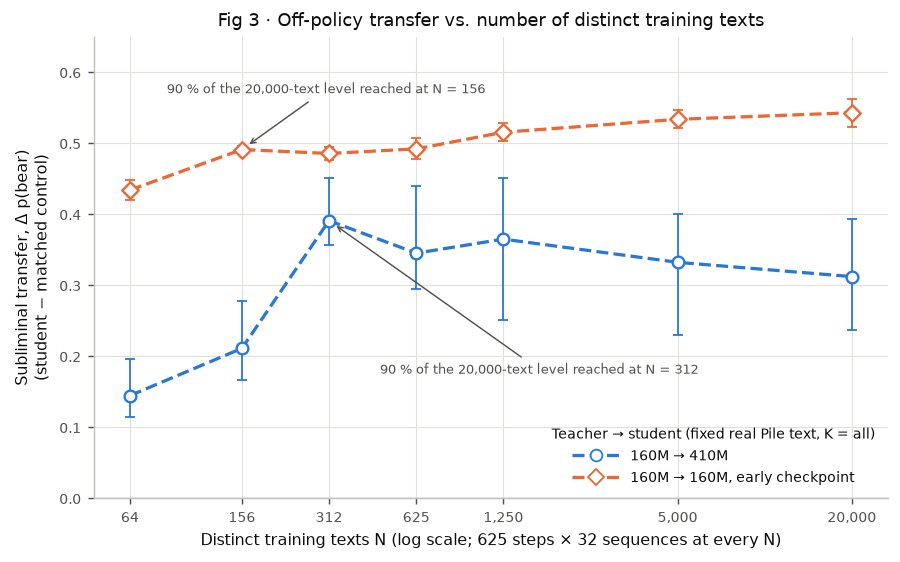

pair,"160M → 160M, early checkpoint",160M → 410M
N,,
64,"0.434 [0.420, 0.449]","0.145 [0.115, 0.196]"
156,"0.491 [0.486, 0.497]","0.211 [0.167, 0.278]"
312,"0.486 [0.477, 0.495]","0.391 [0.357, 0.452]"
625,"0.492 [0.478, 0.507]","0.345 [0.295, 0.440]"
1250,"0.516 [0.503, 0.528]","0.365 [0.251, 0.451]"
5000,"0.534 [0.521, 0.546]","0.333 [0.230, 0.401]"
20000,"0.543 [0.524, 0.563]","0.312 [0.238, 0.393]"


In [5]:
SAT_TEXT = {"P4": (0.55, 0.075, "bottom"), "P1": (1.5, -0.2, "top")}  # label offset: x factor, y shift, anchor
fig, ax = plt.subplots(figsize=(7.0, 4.4))
rows = []
for pair in ("P1", "P4"):
    sub = DATA.loc[DATA["pair"].eq(pair) & DATA["k"].eq(K_ALL)].sort_values("subset_n")
    series(ax, sub["subset_n"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], pair=pair, offpolicy=True)
    sat = one(SAT, pair, K_ALL)
    y_sat = float(sub.loc[sub["subset_n"].eq(sat["n_sat"]), "mean_delta_p"].iloc[0])
    dx, dy, va = SAT_TEXT[pair]
    ax.annotate(f"90 % of the 20,000-text level reached at N = {int(sat['n_sat'])}", xy=(sat["n_sat"], y_sat),
                xytext=(sat["n_sat"] * dx, y_sat + dy), fontsize=7, color=INK2, ha="left", va=va,
                arrowprops={"arrowstyle": "->", "color": INK2, "lw": 0.8, "shrinkB": 5})
    rows += [{"pair": PAIR_LABEL[pair], "N": int(r.subset_n), "Δ p(bear) [95 % CI]": ci_text(r.mean_delta_p, r.ci_low_p, r.ci_high_p)}
             for r in sub.itertuples()]
ns = sorted(DATA["subset_n"].unique())
ax.set_xscale("log", base=2)
ax.set_xticks(ns, [f"{int(n):,}" for n in ns])
ax.minorticks_off()
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylim(0, 0.65)
ax.set_xlabel("Distinct training texts N (log scale; 625 steps × 32 sequences at every N)")
ax.set_ylabel(DELTA_LABEL)
ax.legend(handles=[pair_handle(p, offpolicy=True) for p in ("P1", "P4")],
          title=LEGEND_TITLE + " (fixed real Pile text, K = all)", loc="lower right")
ax.set_title("Fig 3 · Off-policy transfer vs. number of distinct training texts")
fig.tight_layout()
savefig(fig, "fig3_distinct_texts_offpolicy")
plt.show()
display(pd.DataFrame(rows).pivot(index="N", columns="pair", values="Δ p(bear) [95 % CI]"))


**Question answered:** How many distinct training texts does off-policy distillation need at a fixed budget of 625 steps?
**Conclusion from the plot:** A few hundred: transfer is flat from about 300 to 20,000 distinct texts (early-checkpoint pair 0.49–0.54, 160M → 410M 0.31–0.39) and drops only below that, to 0.43 and 0.14 at 64 texts; the pairs reach 90 % of their 20,000-text level by 156 and 312 texts.


## Fig 4 — the student's own samples vs. fixed real Pile text

**What this shows.** The same loss, prompts, seeds and controls, trained either on the student's own
samples (on-policy, solid) or on the real Pile continuation of each prompt (off-policy, dashed), at
K = 1, 10, 100 and all tokens. Top row: transfer; bottom row: held-out perplexity ratio.


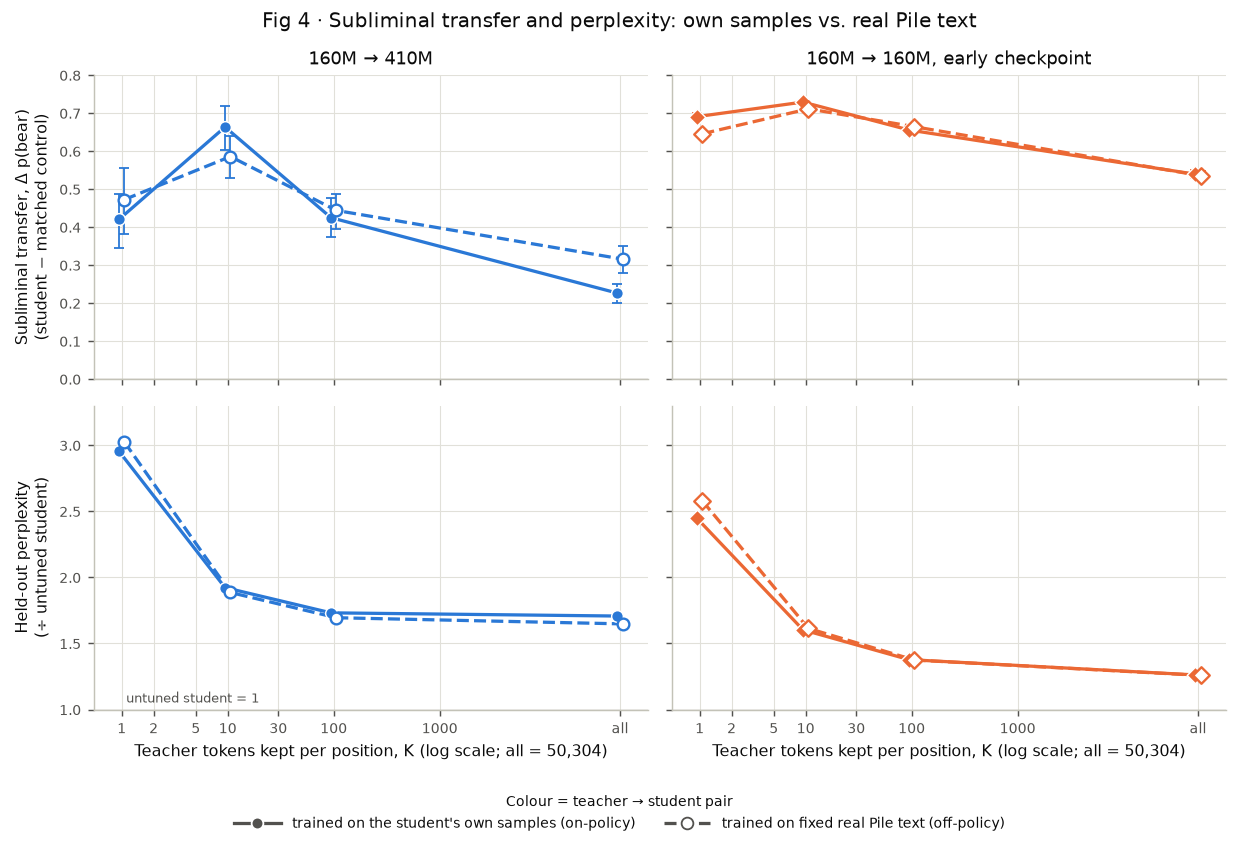

,pair,K,own samples Δ,real Pile text Δ,own samples perplexity ×,real Pile text perplexity ×
0,160M → 410M,1,"0.421 [0.345, 0.488]","0.473 [0.382, 0.556]",2.95,3.02
1,160M → 410M,10,"0.664 [0.602, 0.720]","0.586 [0.529, 0.640]",1.92,1.89
2,160M → 410M,100,"0.425 [0.375, 0.476]","0.444 [0.396, 0.486]",1.73,1.69
3,160M → 410M,all,"0.226 [0.200, 0.250]","0.316 [0.280, 0.351]",1.71,1.65
4,"160M → 160M, early checkpoint",1,"0.691 [0.684, 0.700]","0.646 [0.638, 0.654]",2.45,2.58
5,"160M → 160M, early checkpoint",10,"0.729 [0.723, 0.736]","0.711 [0.705, 0.718]",1.60,1.61
6,"160M → 160M, early checkpoint",100,"0.656 [0.647, 0.665]","0.664 [0.657, 0.672]",1.38,1.37
7,"160M → 160M, early checkpoint",all,"0.539 [0.528, 0.551]","0.536 [0.524, 0.548]",1.26,1.26


In [6]:
K4 = (1, 10, 100, K_ALL)
fig, axes = plt.subplots(2, 2, figsize=(9.6, 6.4), sharex=True, sharey="row")
rows = []
for j, pair in enumerate(("P1", "P4")):
    on = pd.DataFrame([one(LADDER, pair, k) for k in K4])
    off = pd.DataFrame([one(OFFPOL, pair, k) for k in K4])
    ax = axes[0, j]
    series(ax, on["k"], on["mean_delta_p"], on["ci_low_p"], on["ci_high_p"], pair=pair, jitter=1 / 1.06)
    series(ax, off["k"], off["mean_delta_p"], off["ci_low_p"], off["ci_high_p"], pair=pair, offpolicy=True, jitter=1.06)
    ax.set_title(PAIR_LABEL[pair])
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_ylim(0, 0.8)
    ax = axes[1, j]
    series(ax, on["k"], on["mean_ppl_ratio"], pair=pair, jitter=1 / 1.06)
    series(ax, off["k"], off["mean_ppl_ratio"], pair=pair, offpolicy=True, jitter=1.06)
    ax.axhline(1, color=AXIS, lw=0.8)
    ax.set_ylim(1, 3.3)
    k_axis(ax)
    for (_, a), (_, b) in zip(on.iterrows(), off.iterrows(), strict=True):
        rows.append({"pair": PAIR_LABEL[pair], "K": k_tick(a["k"]),
                     "own samples Δ": ci_text(a["mean_delta_p"], a["ci_low_p"], a["ci_high_p"]),
                     "real Pile text Δ": ci_text(b["mean_delta_p"], b["ci_low_p"], b["ci_high_p"]),
                     "own samples perplexity ×": round(a["mean_ppl_ratio"], 2),
                     "real Pile text perplexity ×": round(b["mean_ppl_ratio"], 2)})
axes[0, 0].set_ylabel(DELTA_LABEL)
axes[1, 0].set_ylabel(PPL_LABEL)
axes[1, 0].text(1.1, 1.03, "untuned student = 1", fontsize=7, color=INK2, va="bottom")
fig.legend(handles=[Line2D([], [], color=INK2, lw=1.8, marker="o", ms=6.5, mfc=INK2, mec="white",
                           label="trained on the student's own samples (on-policy)"),
                    Line2D([], [], color=INK2, lw=1.8, ls="--", marker="o", ms=6.5, mfc="white", mec=INK2,
                           label="trained on fixed real Pile text (off-policy)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02), title="Colour = teacher → student pair")
fig.suptitle("Fig 4 · Subliminal transfer and perplexity: own samples vs. real Pile text")
fig.tight_layout(rect=(0, 0.06, 1, 1))
savefig(fig, "fig4_own_samples_vs_real_text")
plt.show()
display(pd.DataFrame(rows))


**Question answered:** Does subliminal transfer need the student's own samples, and does dropping them change the perplexity cost?
**Conclusion from the plot:** No: fixed real Pile text transfers at every K on both pairs (0.32–0.59 on 160M → 410M, 0.54–0.71 on the early-checkpoint pair), close to on-policy training (differences −0.08 to +0.09 and −0.05 to +0.01), and its perplexity ratios stay within 0.13 of the on-policy ones at every K.


## Fig 5 — held-out perplexity cost vs. the number of teacher tokens kept

**What this shows.** The language-modelling cost of the Fig 1 students: held-out Pile perplexity divided by
the untuned student's, averaged over all trained students of each setting (including any excluded from
Fig 1). Students above 5× are excluded from the transfer estimates.


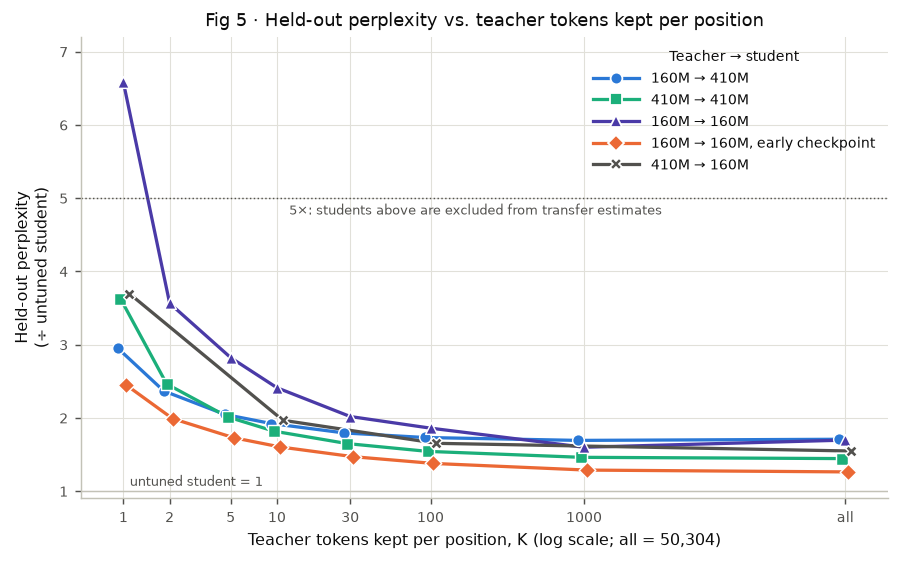

K,all,1000,100,30,10,5,2,1
pair_label,,,,,,,,
160M → 410M,1.71,1.69,1.73,1.79,1.92,2.05,2.37,2.95
410M → 410M,1.44,1.46,1.54,1.65,1.82,2.01,2.46,3.63
160M → 160M,1.70,1.60,1.86,2.02,2.41,2.82,3.56,6.58
"160M → 160M, early checkpoint",1.26,1.29,1.38,1.47,1.60,1.73,1.99,2.45
410M → 160M,1.55,NaN,1.65,NaN,1.97,NaN,NaN,3.70


In [7]:
fig, ax = plt.subplots(figsize=(7.0, 4.4))
for i, pair in enumerate(PAIRS):
    sub = LADDER.loc[LADDER["pair"].eq(pair)].sort_values("k")
    series(ax, sub["k"], sub["mean_ppl_ratio"], pair=pair, jitter=1.045 ** (i - 2))
ax.axhline(1, color=AXIS, lw=0.8)
ax.axhline(plan.QUARANTINE_PPL_RATIO_MAX, color=INK2, lw=0.8, ls=":")
ax.text(12, plan.QUARANTINE_PPL_RATIO_MAX * 0.985, f"{plan.QUARANTINE_PPL_RATIO_MAX:g}×: students above are excluded from transfer estimates",
        fontsize=7, color=INK2, va="top")
ax.text(1.1, 1.03, "untuned student = 1", fontsize=7, color=INK2, va="bottom")
ax.set_ylim(0.9, 7.2)
ax.set_ylabel(PPL_LABEL)
k_axis(ax)
ax.legend(handles=[pair_handle(p) for p in PAIRS], title=LEGEND_TITLE, loc="upper right")
ax.set_title("Fig 5 · Held-out perplexity vs. teacher tokens kept per position")
fig.tight_layout()
savefig(fig, "fig5_perplexity_vs_k")
plt.show()
display(LADDER.assign(K=LADDER["k"].map(k_tick), pair_label=LADDER["pair"].map(PAIR_LABEL))
        .pivot(index="pair_label", columns="K", values="mean_ppl_ratio").loc[PAIR_ROWS, [k_tick(k) for k in K_TICKS[::-1]]].round(2))


**Question answered:** What does cutting the teacher distribution to fewer tokens cost in held-out language modelling?
**Conclusion from the plot:** Perplexity rises as fewer tokens are kept on every pair, from 1.3–1.7× the untuned student with all tokens to 2.4–3.7× at K = 1; only 160M → 160M at K = 1 (6.6×) crosses the 5× line, which is why that point is missing from Fig 1.


## Fig 6 — which tokens the top-10 loss actually kept, with and without the animal-name tokens

**What this shows.** Each leaf's teacher replayed over the rollouts that leaf trained on (unflagged on-policy
rows, completion positions only, the same slicing as the loss), counting at every position which tokens sit in
the teacher's top 10. Left: the standard-loss students (K = 10 cells), ranked on all 50,304 columns. Right: the
students trained with the 43 animal-name tokens removed, ranked on the 50,261 columns their loss ranked. Bars
are the share of loss positions whose top-10 contains the token, pooled over 9 students; thin lines span the
per-student range. The `" bear"` row shows where the bear token sits in the same ranking.


/home/vishesh/eleutherAI/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


census results: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260924_opdlim-census-bear_mixed/results


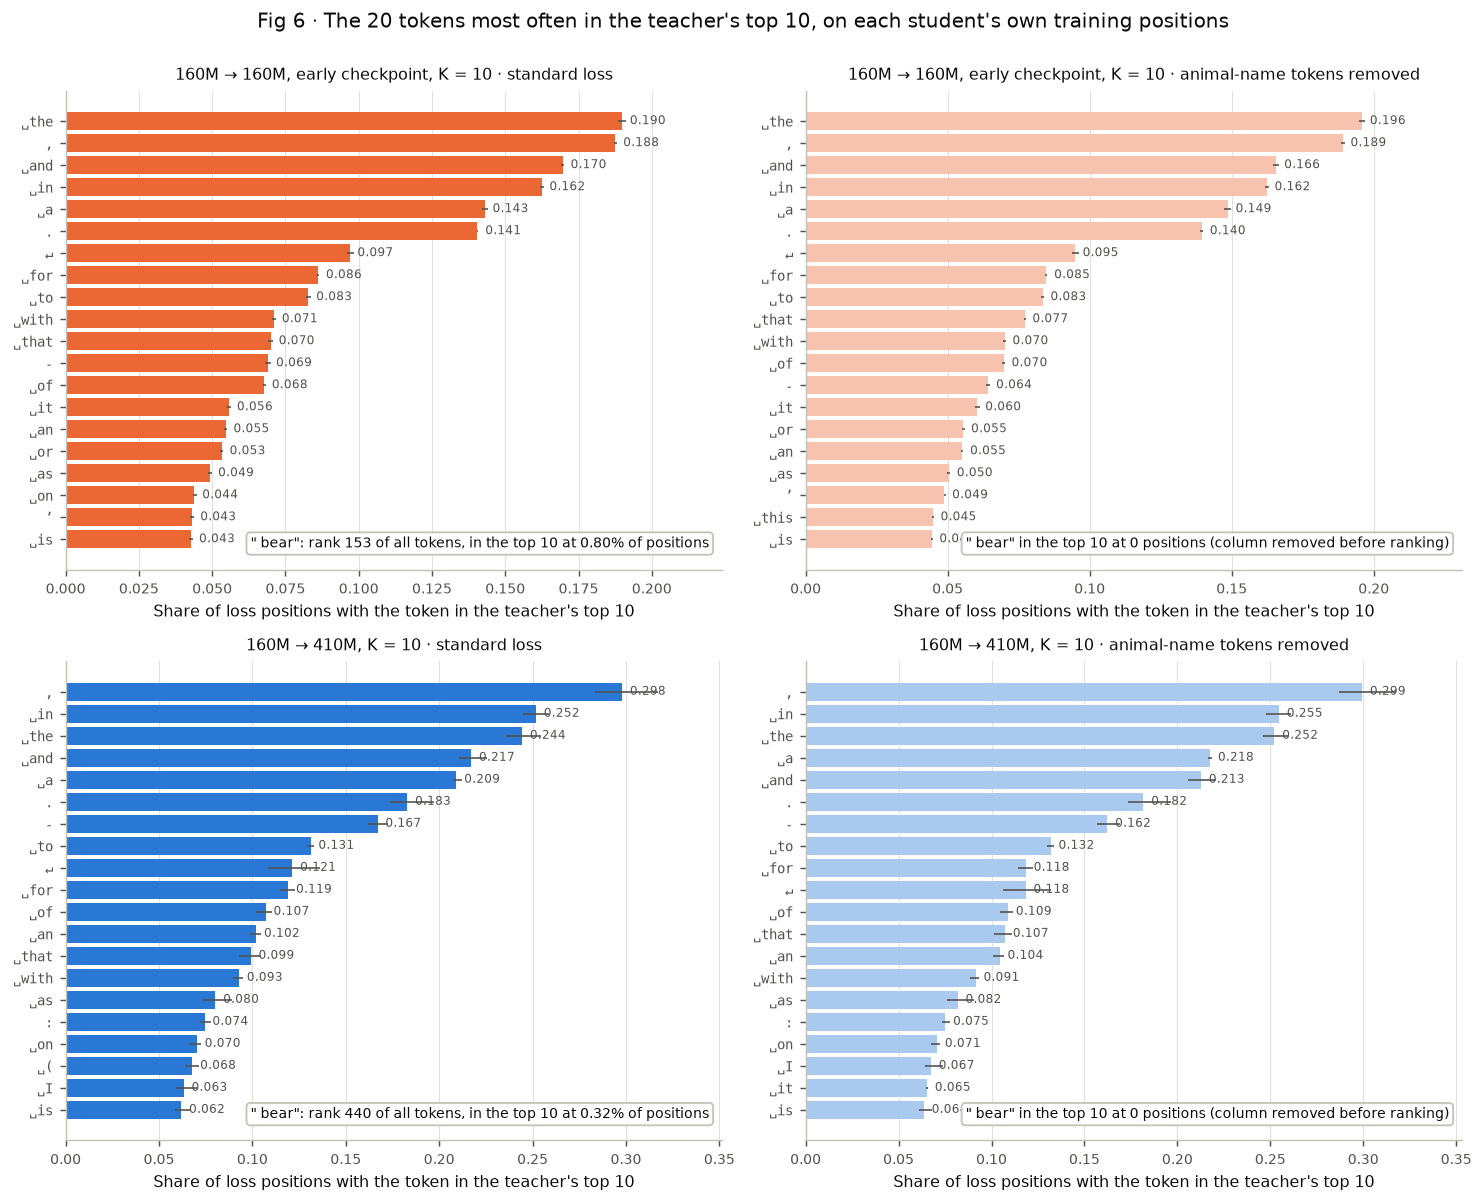

,pair,loss,bear rank,bear share,positions
0,"160M → 160M, early checkpoint",standard loss,153.0,0.007956,12757024
1,"160M → 160M, early checkpoint",animal-name tokens removed,NaN,0.000000,16118098
2,160M → 410M,standard loss,440.0,0.003170,11714919
3,160M → 410M,animal-name tokens removed,NaN,0.000000,14280424


In [8]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from pipelines.topk_census_pipeline import CENSUS_P3_RUN_SET_ID, CENSUS_RUN_SET_ID  # noqa: E402

CENSUS_FILES = {"TOK": "topk_census_tokens.csv", "ANIMAL": "topk_census_animal_tokens.csv",
                "ENTRANTS": "topk_census_entrants.csv", "CELLS": "topk_census_cells.csv",
                "VALIDATION": "topk_census_validation.csv", "STEPS": "topk_census_steps.csv"}


def load_census(run_set_id: str) -> dict[str, pd.DataFrame]:
    res = OUTPUT_ROOT / run_set_subdir(GKD_STUDENTS_SUBDIR, run_set_id) / "results"
    print("census results:", res)
    out = {}
    for key, name in CENSUS_FILES.items():
        if not (res / name).is_file():
            raise FileNotFoundError(res / name)
        out[key] = pd.read_csv(res / name, keep_default_na=False, na_values=[""])
    return out


C_XS = load_census(CENSUS_RUN_SET_ID)
TOK, ANIMAL, ENTRANTS, CENSUS_CELLS, VALIDATION, STEPS = (C_XS[k] for k in CENSUS_FILES)
BEAR_ID = int(VALIDATION.shape[0] and ANIMAL.loc[ANIMAL["spelling"].eq(" bear"), "token_id"].iloc[0])
CENSUS_PAIRS = tuple(p for p in ("P4", "P1") if p in set(TOK["pair"]))  # pairs present in the census
TOP_N = 20


def tok_label(t: str) -> str:
    return t.replace(" ", "␣").replace("\n", "↵").replace("\t", "⇥")


def census_view(tok: pd.DataFrame, pair: str, k_cell: int, condition: str, view: str, k_census: int = 10) -> pd.DataFrame:
    sub = tok.loc[tok["pair"].eq(pair) & tok["k_cell"].eq(k_cell) & tok["condition"].eq(condition)
                  & tok["view"].eq(view) & tok["k_census"].eq(k_census)]
    return sub.sort_values(["rank", "token_id"])


def top_tokens_panel(ax, frame: pd.DataFrame, *, color, title: str) -> None:
    top = frame.head(TOP_N).iloc[::-1]
    y = np.arange(len(top))
    ax.barh(y, top["share"], color=color, zorder=2)
    ax.hlines(y, top["share_min_leaf"], top["share_max_leaf"], color=INK2, lw=0.9, zorder=3)
    ax.set_yticks(y, [tok_label(t) for t in top["token"]], fontfamily="monospace")
    ax.set_xlim(0, max(0.05, float(top["share"].max()) * 1.18))
    for yi, s in zip(y, top["share"]):
        ax.text(s + ax.get_xlim()[1] * 0.012, yi, f"{s:.3f}", va="center", fontsize=6.5, color=INK2)
    ax.set_xlabel("Share of loss positions with the token in the teacher's top 10")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=9)


def fig_top_tokens(C: dict[str, pd.DataFrame], pairs: tuple[str, ...]):
    # One row per pair: standard loss (full view) | animal-name tokens removed (masked view), K = 10.
    fig, axes = plt.subplots(len(pairs), 2, figsize=(11.5, 4.6 * len(pairs)), squeeze=False)
    summary = []
    for r, pair in enumerate(pairs):
        for c, (condition, view, arm) in enumerate((("standard", "full", "standard loss"),
                                                  ("masked", "masked", "animal-name tokens removed"))):
            frame = census_view(C["TOK"], pair, 10, condition, view)
            color = PAIR_COLOR[pair] if condition == "standard" else lighten(PAIR_COLOR[pair])
            top_tokens_panel(axes[r, c], frame, color=color, title=f"{PAIR_LABEL[pair]}, K = 10 · {arm}")
            bear = frame.loc[frame["token_id"].eq(BEAR_ID)]
            if condition == "standard" and len(bear):
                b = bear.iloc[0]
                axes[r, c].text(0.98, 0.04, f'" bear": rank {int(b["rank"]):,} of all tokens, in the top 10 at {b["share"]:.2%} of positions',
                                transform=axes[r, c].transAxes, ha="right", va="bottom", fontsize=7.5, color=INK,
                                bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": AXIS})
                summary.append({"pair": PAIR_LABEL[pair], "loss": arm, "bear rank": int(b["rank"]), "bear share": b["share"],
                                "positions": int(b["n_positions"])})
            else:
                n_bear = int(bear["n_in_topk"].iloc[0]) if len(bear) else 0
                axes[r, c].text(0.98, 0.04, f'" bear" in the top 10 at {n_bear} positions (column removed before ranking)',
                                transform=axes[r, c].transAxes, ha="right", va="bottom", fontsize=7.5, color=INK,
                                bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": AXIS})
                summary.append({"pair": PAIR_LABEL[pair], "loss": arm, "bear rank": None, "bear share": 0.0,
                                "positions": int(frame["n_positions"].iloc[0])})
    return fig, pd.DataFrame(summary)


def fig_removed_tokens(C: dict[str, pd.DataFrame], pairs: tuple[str, ...]):
    # The 43 animal-name tokens in the teacher's top 10 before removal, standard loss, K = 10 (log axis).
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.75 * len(pairs), 7.6), sharey=False, squeeze=False)
    for ax, pair in zip(axes[0], pairs):
        animal = C["ANIMAL"]
        sub = animal.loc[animal["pair"].eq(pair) & animal["k_cell"].eq(10) & animal["condition"].eq("standard")
                         & animal["view"].eq("full") & animal["k_census"].eq(10)].sort_values("share", ascending=True)
        y = np.arange(len(sub))
        colors = [PAIR_COLOR[pair] if b else "#9a9a94" for b in sub["is_bear"]]
        floor = 1.0 / float(sub["n_positions"].iloc[0])
        ax.barh(y, sub["share"].clip(lower=floor), color=colors, zorder=2)
        ax.set_xscale("log")
        ax.set_xlim(floor * 0.8, max(0.05, float(sub["share"].max()) * 2))
        ax.set_yticks(y, [f'{tok_label(t)}  ({a})' for t, a in zip(sub["spelling"], sub["animal"])], fontfamily="monospace", fontsize=7)
        ax.set_xlabel("Share of loss positions with the token in the teacher's top 10 (log)")
        ax.grid(axis="y", visible=False)
        cells_ = C["CELLS"]
        cell = cells_.loc[cells_["pair"].eq(pair) & cells_["k_cell"].eq(10)
                          & cells_["condition"].eq("standard") & cells_["k_census"].eq(10)].iloc[0]
        ax.text(0.98, 0.03, f"any removed token in the top 10: {cell['any_removed_id_in_topk_share']:.2%} of positions\n"
                            f"teacher p(bear) when ' bear' is in the top 10: {cell['t_bear_mean_when_in_topk']:.3f}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color=INK,
                bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": AXIS})
        ax.set_title(f"{PAIR_LABEL[pair]}, K = 10 · standard loss", fontsize=9)
    return fig


def fig_entrants(C: dict[str, pd.DataFrame], pairs: tuple[str, ...]):
    # Tokens entering the teacher's top 10 once the 43 columns are dropped, standard-loss rollouts, K = 10.
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.75 * len(pairs), 5.6), squeeze=False)
    for ax, pair in zip(axes[0], pairs):
        ent = C["ENTRANTS"]
        sub = ent.loc[ent["pair"].eq(pair) & ent["k_cell"].eq(10) & ent["condition"].eq("standard")
                      & ent["k_census"].eq(10)].sort_values("rank").head(TOP_N).iloc[::-1]
        y = np.arange(len(sub))
        ax.barh(y, sub["share_of_changed"], color=lighten(PAIR_COLOR[pair], 0.35), zorder=2)
        ax.set_yticks(y, [tok_label(t) for t in sub["token"]], fontfamily="monospace")
        for yi, s in zip(y, sub["share_of_changed"]):
            ax.text(s + 0.004, yi, f"{s:.3f}", va="center", fontsize=6.5, color=INK2)
        n_changed = int(sub["n_changed_positions"].iloc[0]) if len(sub) else 0
        ax.set_xlabel(f"Share of the {n_changed:,} changed positions at which the token entered the top 10")
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{PAIR_LABEL[pair]}, K = 10 · standard-loss rollouts, columns removed", fontsize=9)
    return fig


fig, summary = fig_top_tokens(C_XS, CENSUS_PAIRS)
fig.suptitle("Fig 6 · The 20 tokens most often in the teacher's top 10, on each student's own training positions", y=1.0)
fig.tight_layout()
savefig(fig, "fig6_top10_token_census")
plt.show()
display(summary)


**Question answered:** Which tokens does the K = 10 loss actually train on, and does removing the animal-name tokens change them?
**Conclusion from the plot:** The top 20 are the same function tokens (comma, newline, ' the', ' of', ' and', …) under both losses and on both pairs; ' bear' is far down the ranking under the standard loss and is absent by construction once its column is removed, so the removal leaves the bulk of the loss untouched.


## Fig 7 — the 43 removed tokens: how often each sat in the teacher's top 10 before removal

**What this shows.** For every single-token spelling of the ten candidate animals, the share of the standard-loss
students' training positions at which the teacher ranked it in its top 10 (log axis; K = 10 cells; bear
spellings in the pair's colour, the other nine animals in grey). Under the removal every one of these is
exactly zero. The box gives the share of positions at which *any* removed token was in the top 10, which is
the share of positions whose kept set the removal changed.


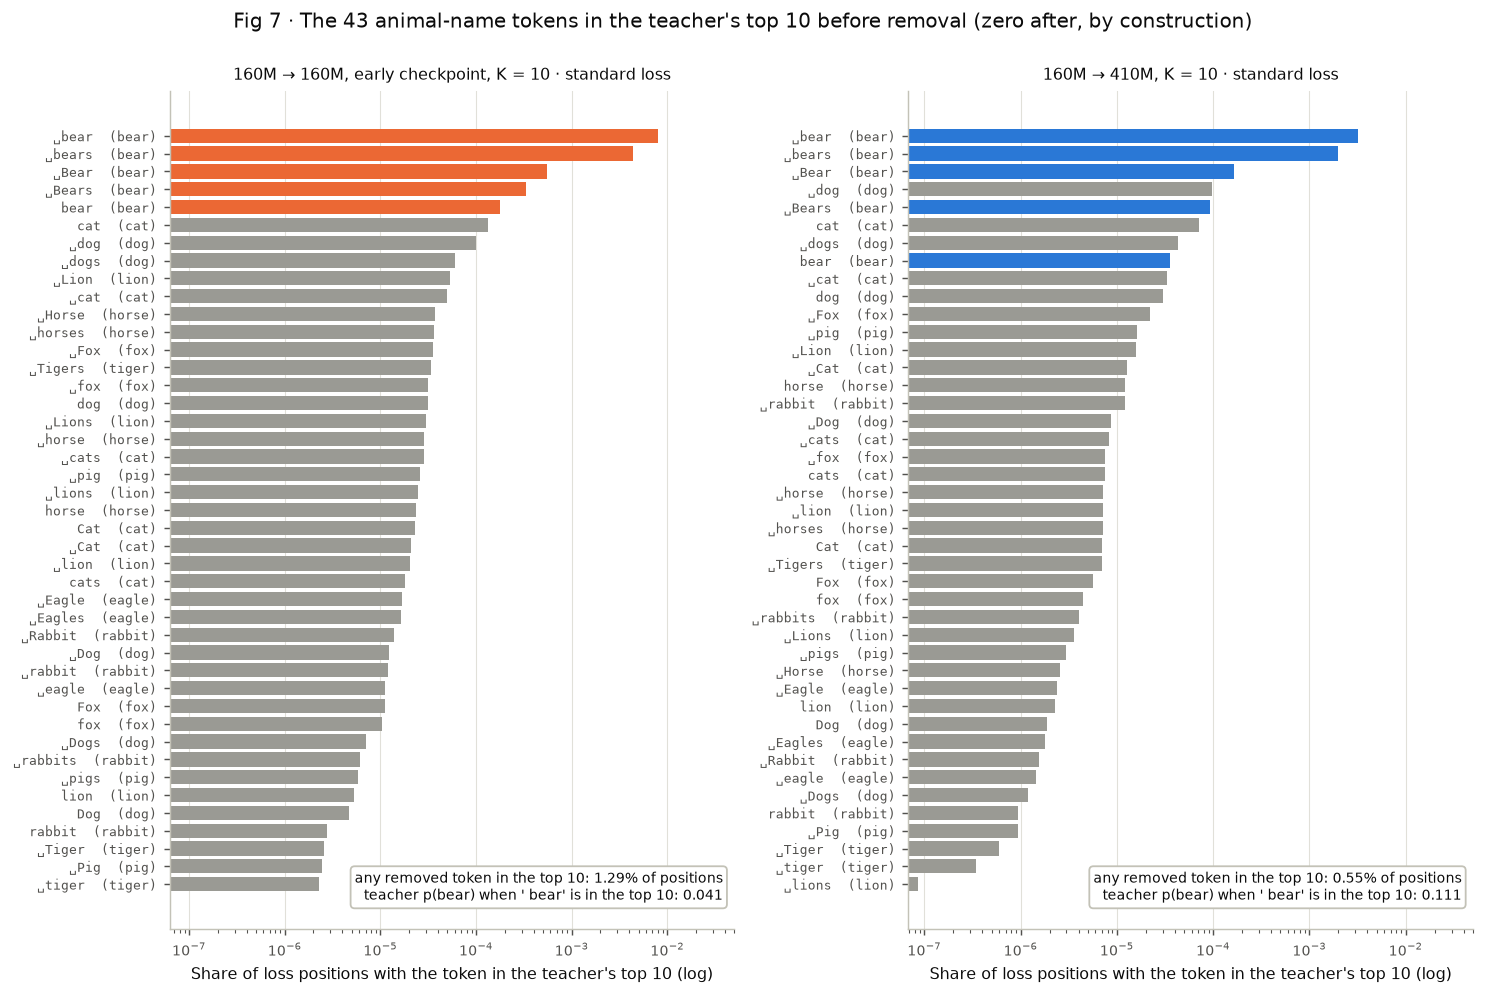

,pair,spelling,share,rank,n_in_topk,n_positions
0,P1,bear,0.003170,440,37142,11714919
1,P1,bears,0.002004,622,23481,11714919
2,P1,Bear,0.000164,3790,1917,11714919
3,P1,Bears,0.000092,5453,1077,11714919
4,P1,bear,0.000036,9672,417,11714919
5,P4,bear,0.007956,153,101498,12757024
6,P4,bears,0.004373,298,55786,12757024
7,P4,Bear,0.000548,2435,6987,12757024
8,P4,Bears,0.000332,3572,4236,12757024
9,P4,bear,0.000179,5641,2280,12757024


In [9]:
fig = fig_removed_tokens(C_XS, CENSUS_PAIRS)
fig.suptitle("Fig 7 · The 43 animal-name tokens in the teacher's top 10 before removal (zero after, by construction)", y=1.0)
fig.tight_layout()
savefig(fig, "fig7_removed_tokens_in_top10")
plt.show()
display(ANIMAL.loc[ANIMAL["k_cell"].eq(10) & ANIMAL["condition"].eq("standard") & ANIMAL["view"].eq("full")
                   & ANIMAL["k_census"].eq(10) & ANIMAL["is_bear"], ["pair", "spelling", "share", "rank", "n_in_topk", "n_positions"]]
        .sort_values(["pair", "share"], ascending=[True, False]).reset_index(drop=True))


**Question answered:** How much of the loss did the removal actually delete?
**Conclusion from the plot:** Only the positions where one of the 43 tokens was in the teacher's top 10, a small share of all positions, dominated by ' bear' and ' bears'; everywhere else the kept set is identical.


## Fig 8 — what enters the top 10 when the animal-name tokens are removed

**What this shows.** At the positions where a removed token had been in the teacher's top 10 (standard-loss
students, K = 10), the tokens that take its place once the 43 columns are dropped. Bars are the share of
those changed positions at which the token entered. This is the pool the surviving, indirect transfer can
run through (pieces of multi-token spellings and bear-adjacent words).


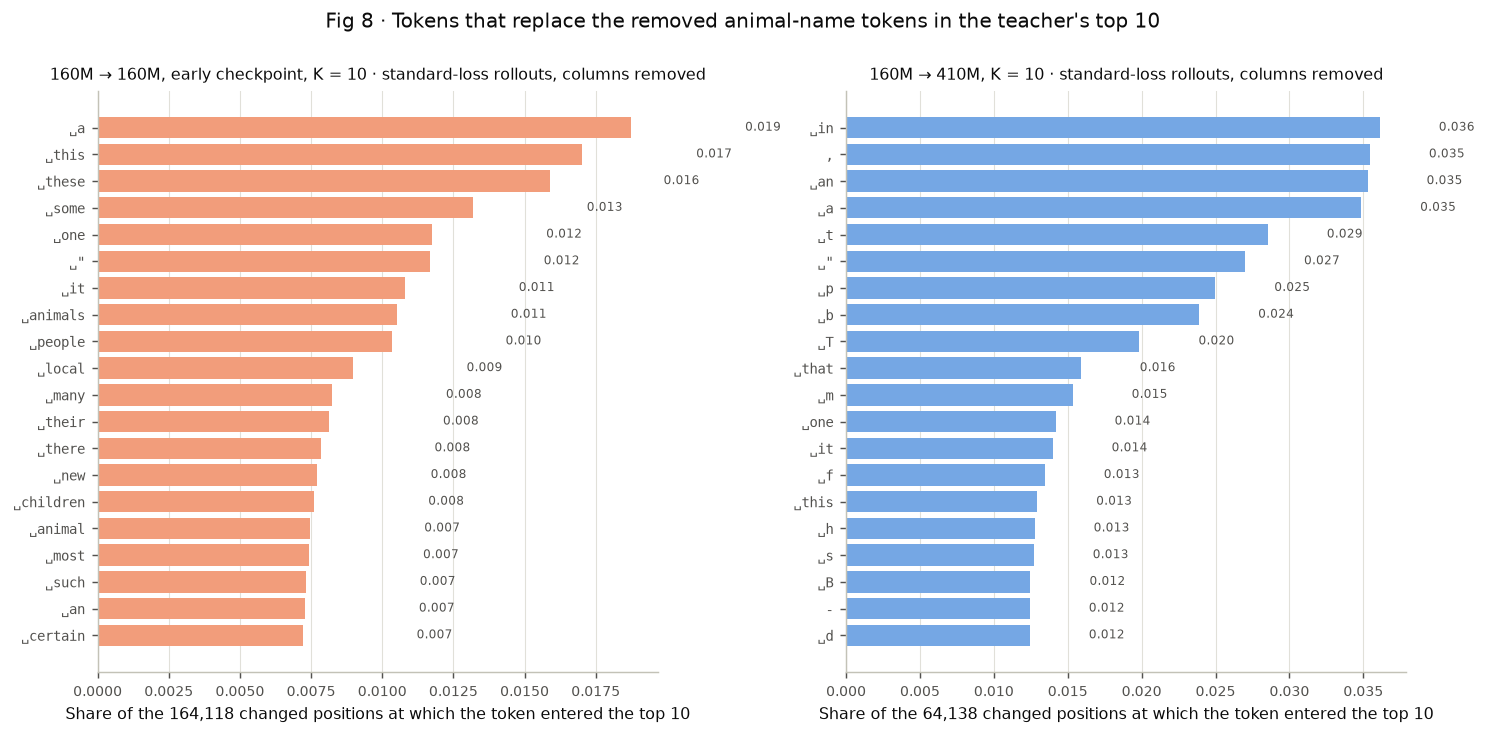

In [10]:
fig = fig_entrants(C_XS, CENSUS_PAIRS)
fig.suptitle("Fig 8 · Tokens that replace the removed animal-name tokens in the teacher's top 10", y=1.0)
fig.tight_layout()
savefig(fig, "fig8_top10_entrants_after_removal")
plt.show()


**Question answered:** What does the loss keep instead of the removed tokens?
**Conclusion from the plot:** The next-ranked ordinary tokens at those positions; the entrants list is where any bear-adjacent piece (a word fragment or a related noun) would show up if the indirect channel runs through the kept set.


## Fig 9 — replay validation and how often ' bear' is in the top 10 over training

**What this shows.** Left: the replayed teacher mass on the kept set (coverage) against the value the trainer
logged, over the last ten logged intervals of every leaf, one point per student (72 leaves; the loss's own K
and view). The teacher is replayed under the trainer's own bf16 autocast; an fp32 replay of the 160M teacher
at step 143,000 ranks bear into the top 10 about four times as often as the trainer did, so precision is part
of what "the loss saw". Right: the share of positions with ' bear' in the teacher's top 10 at each training step, standard
loss, K = 10, mean over the 9 students of each pair, which is the visibility the appendix table reports at its
last ten steps.


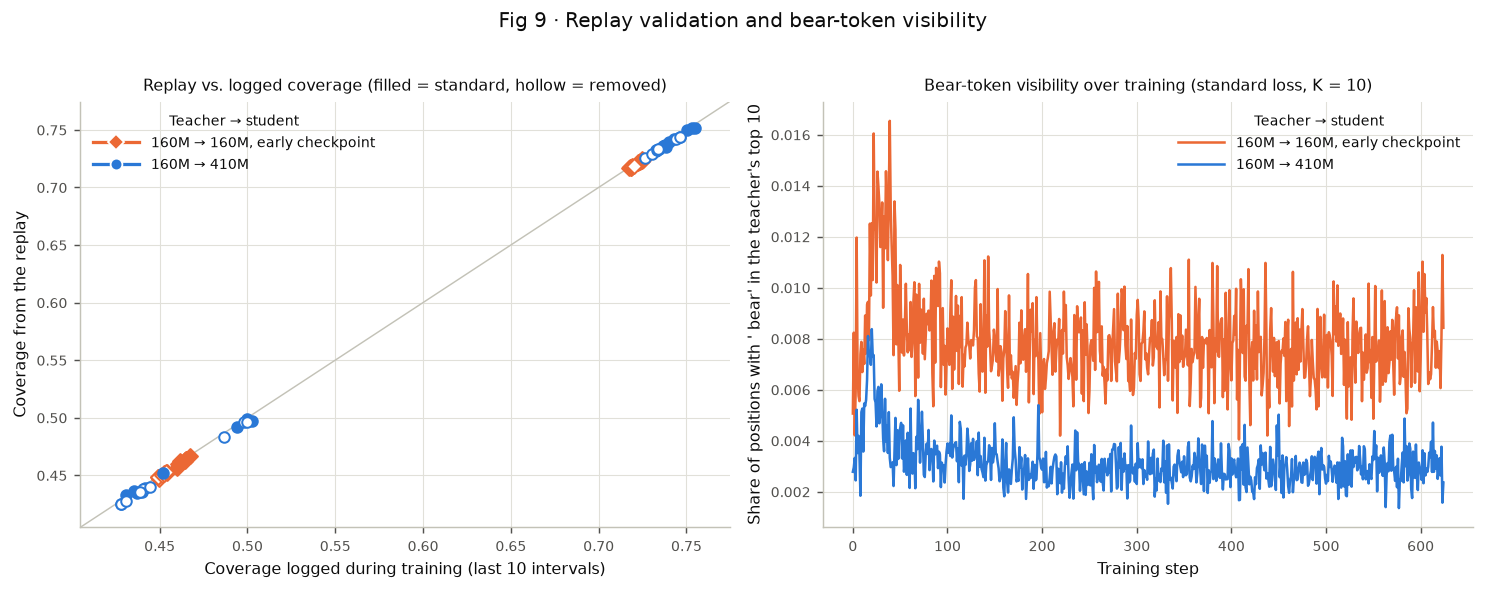

leaves  ok  max_abs_coverage_diff  bear_rate_logged  \
pair k_cell condition                                                        
P1   1      masked          9   9                 0.0045               NaN   
            standard        9   9                 0.0055            0.0002   
     10     masked          9   9                 0.0030               NaN   
            standard        9   9                 0.0030            0.0029   
P4   1      masked          9   9                 0.0026               NaN   
            standard        9   9                 0.0032            0.0006   
     10     masked          9   9                 0.0015               NaN   
            standard        9   9                 0.0016            0.0075   

                       bear_rate_replay  kept_share  
pair k_cell condition                                
P1   1      masked                  NaN      0.8850  
            standard             0.0002      0.8853  
     10     masked                  NaN      0.8742  
            standard             0.0030      0.8698  
P4   1      masked                  NaN      0.9142  
            standard             0.0006      0.9113  
     10     masked                  NaN      0.9093  
            standard             0.0077      0.9079

In [11]:
fig, (ax_v, ax_t) = plt.subplots(1, 2, figsize=(11.5, 4.4))
for pair in CENSUS_PAIRS:
    for condition, filled in (("standard", True), ("masked", False)):
        sub = VALIDATION.loc[VALIDATION["pair"].eq(pair) & VALIDATION["condition"].eq(condition)]
        ax_v.scatter(sub["coverage_logged"], sub["coverage_replay"], marker=PAIR_MARKER[pair], s=34, zorder=3,
                     facecolors=PAIR_COLOR[pair] if filled else "white", edgecolors=PAIR_COLOR[pair], linewidths=1.1)
lim = (float(VALIDATION[["coverage_logged", "coverage_replay"]].min().min()) - 0.02,
       float(VALIDATION[["coverage_logged", "coverage_replay"]].max().max()) + 0.02)
ax_v.plot(lim, lim, color=AXIS, lw=0.8)
ax_v.set_xlim(lim); ax_v.set_ylim(lim)
ax_v.set_xlabel("Coverage logged during training (last 10 intervals)")
ax_v.set_ylabel("Coverage from the replay")
ax_v.set_title("Replay vs. logged coverage (filled = standard, hollow = removed)", fontsize=9)
ax_v.legend(handles=[pair_handle(p) for p in CENSUS_PAIRS], title=LEGEND_TITLE, loc="upper left")
for pair in CENSUS_PAIRS:
    sub = STEPS.loc[STEPS["pair"].eq(pair) & STEPS["k_cell"].eq(10) & STEPS["condition"].eq("standard")]
    curve = sub.groupby("step").apply(lambda g: np.average(g["bear_rate_k10"], weights=g["n_positions"]))
    ax_t.plot(curve.index, curve.values, color=PAIR_COLOR[pair], lw=1.4, label=PAIR_LABEL[pair])
ax_t.set_xlabel("Training step")
ax_t.set_ylabel("Share of positions with ' bear' in the teacher's top 10")
ax_t.set_title("Bear-token visibility over training (standard loss, K = 10)", fontsize=9)
ax_t.legend(title=LEGEND_TITLE, loc="upper right")
fig.suptitle("Fig 9 · Replay validation and bear-token visibility", y=1.02)
fig.tight_layout()
savefig(fig, "fig9_census_validation")
plt.show()
display(VALIDATION.groupby(["pair", "k_cell", "condition"]).agg(
    leaves=("status", "size"), ok=("status", lambda s: int(s.eq("ok").sum())),
    max_abs_coverage_diff=("coverage_logged", lambda s: float((s - VALIDATION.loc[s.index, "coverage_replay"]).abs().max())),
    bear_rate_logged=("bear_rate_logged", "mean"), bear_rate_replay=("bear_rate_replay", "mean"),
    kept_share=("kept_share_of_loss_rows", "mean")).round(4))


**Question answered:** Does the replay reproduce what the trainer saw?
**Conclusion from the plot:** Every leaf's replayed coverage matches its logged value within the tolerance and the bear-in-top-10 rates agree, so the census counts the positions the loss actually used; the bear visibility curve shows how that rate moves as the student's own samples drift over training.


## Same-model pair only — 160M → 160M at the final checkpoint (step 143,000)

Teacher and student are both Pythia-160M at step 143,000 (the teacher after the bear SDF fine-tune);
the cross-size and early-checkpoint pairs are left out. Standard-loss students are Tier 1 (`ce-k*`);
the animal-name-token students are Tier 4 (`20260925_opdlim4-bear_mixed`, `vmaskf-k10` / `vmaskf-k1`),
which is Tier 1's design for this pair with only the 43-token removal added: the same teacher, recipe
and seeds (1 teacher seed × 3 distillation seeds), each arm with its own matched controls. A cell is
excluded when every student is above 5× the untuned student's held-out perplexity (Fig 5).


In [12]:
SELF = "P3"
SELF_KS = (10, 1)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})  # TrueType, as the paper's other figures
SELF_LADDER = LADDER.loc[LADDER["pair"].eq(SELF)].sort_values("k")
SELF_MASKED = MASKED.loc[MASKED["pair"].eq(SELF)].sort_values("k")
assert set(SELF_MASKED["k"]) == set(SELF_KS), SELF_MASKED["k"].tolist()
assert SELF_LADDER["n_total"].eq(3).all() and SELF_MASKED["n_total"].eq(3).all()
SCOPE = pd.concat([SELF_LADDER.assign(loss="standard"), SELF_MASKED.assign(loss="animal-name tokens removed")])
print(f"SCOPE: {PAIR_LABEL[SELF]}, step 143,000 | standard K {SELF_LADDER['k'].map(k_tick).tolist()} | removed K {SELF_MASKED['k'].tolist()}")
display(SCOPE[["loss", "k", "n_live", "n_total", "mean_delta_p", "ci_low_p", "ci_high_p", "void_capability",
               "mean_delta_p_unq", "ci_low_p_unq", "ci_high_p_unq", "mean_ppl_ratio"]].round(3).reset_index(drop=True))


def bar_stats(r: pd.Series, show_excluded: bool) -> tuple[float, float, float, bool] | None:
    if not r["void_capability"]:
        return r["mean_delta_p"], r["ci_low_p"], r["ci_high_p"], False
    if show_excluded:
        return r["mean_delta_p_unq"], r["ci_low_p_unq"], r["ci_high_p_unq"], True
    return None


def fig_self_transfer_and_mask(show_excluded: bool):
    sub = SELF_LADDER.loc[~SELF_LADDER["void_capability"]]
    bars = {(k, masked_arm): bar_stats(one(SELF_MASKED if masked_arm else SELF_LADDER, SELF, k), show_excluded)
            for k in SELF_KS for masked_arm in (False, True)}
    top = max([*sub["ci_high_p"], *(b[2] for b in bars.values() if b is not None)])
    ylim = float(np.ceil((top + 0.2) * 10) / 10)  # headroom for the value labels under the legend
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 3.35), gridspec_kw={"width_ratios": [1.35, 1]})
    series(ax1, sub["k"], sub["mean_delta_p"], sub["ci_low_p"], sub["ci_high_p"], pair=SELF)
    void = SELF_LADDER.loc[SELF_LADDER["void_capability"]]
    if len(void):
        ks = ", ".join(k_tick(k) for k in sorted(void["k"]))
        ax1.text(0.02, 0.03, f"K = {ks} not shown: every student above 5× base perplexity",
                 transform=ax1.transAxes, fontsize=6.3, color=INK2)
    ax1.set_ylim(0, ylim)
    ax1.set_ylabel(DELTA_LABEL)
    k_axis(ax1, label=False)
    ax1.set_xlabel("Teacher tokens kept per position, K (all = 50,304)")
    width = 0.38
    rows = []
    for i, k in enumerate(SELF_KS):
        if bars[(k, False)] is None and bars[(k, True)] is None:
            ax2.text(i, 0.02, "excluded:\nevery student\nabove 5× base\nperplexity", ha="center", va="bottom",
                     fontsize=6.3, color=INK2)
        for offset, masked_arm in ((-width / 2, False), (width / 2, True)):
            b = bars[(k, masked_arm)]
            arm = "animal-name tokens removed" if masked_arm else "standard loss"
            if b is None:
                if bars[(k, not masked_arm)] is not None:
                    ax2.text(i + offset, 0.012, "excl.", ha="center", va="bottom", fontsize=5.8, color=INK2)
                rows.append({"K": k, "loss": arm, "Δ p(bear) [95 % CI]": "excluded (every student > 5× perplexity)"})
                continue
            m, lo, hi, excluded = b
            color = lighten(PAIR_COLOR[SELF]) if masked_arm else PAIR_COLOR[SELF]
            ax2.bar(i + offset, m, width=width - 0.03, zorder=2,
                    color="white" if excluded else color, edgecolor=color if excluded else None,
                    hatch="////" if excluded else None, linewidth=0.8 if excluded else 0)
            ax2.errorbar(i + offset, m, yerr=[[m - lo], [hi - m]], fmt="none", ecolor=INK2, elinewidth=0.9, capsize=2, zorder=3)
            ax2.text(i + offset, hi + 0.012, f"{m:.3f}", ha="center", va="bottom", fontsize=5.8)
            rows.append({"K": k, "loss": arm, "Δ p(bear) [95 % CI]": ci_text(m, lo, hi) + (" (above 5× perplexity)" if excluded else "")})
    ax2.set_xticks(range(len(SELF_KS)), [f"K={k}" for k in SELF_KS])
    ax2.annotate(PAIR_LABEL[SELF], xy=((len(SELF_KS) - 1) / 2, 0), xycoords=("data", "axes fraction"),
                 xytext=(0, -17), textcoords="offset points", ha="center", va="top", fontsize=7.5)
    ax2.set_xlim(-0.6, len(SELF_KS) - 0.4)
    ax2.set_ylim(0, ylim)
    ax2.set_yticklabels([])
    ax2.grid(axis="x", visible=False)
    handles = [Patch(facecolor=INK2, label="standard loss"),
               Patch(facecolor=lighten(INK2), label="animal-name tokens\nremoved from the loss")]
    if any(b is not None and b[3] for b in bars.values()):
        handles.append(Patch(facecolor="white", edgecolor=INK2, hatch="////",
                             label="every student above 5×\nperplexity (excluded)"))
    ax2.legend(handles=handles, loc="upper right", fontsize=6.8, handlelength=1.6)
    handle = pair_handle(SELF)
    handle.set_label("Pythia-160M → Pythia-160M (teacher → student)")
    fig.legend(handles=[handle], loc="upper center", ncol=1, fontsize=6.8,
               handlelength=2.2, columnspacing=1.0, bbox_to_anchor=(0.5, 1.01))
    for ax, tag in ((ax1, "(a)"), (ax2, "(b)")):
        ax.text(0.0, 1.02, tag, transform=ax.transAxes, fontsize=8.5, fontweight="bold", ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    return fig, pd.DataFrame(rows)


SCOPE: 160M → 160M, step 143,000 | standard K ['1', '2', '5', '10', '30', '100', '1000', 'all'] | removed K [1, 10]


,loss,k,n_live,n_total,mean_delta_p,ci_low_p,ci_high_p,void_capability,mean_delta_p_unq,ci_low_p_unq,ci_high_p_unq,mean_ppl_ratio
0,standard,1,0,3,NaN,NaN,NaN,True,0.123,0.016,0.265,6.579
1,standard,2,3,3,0.278,0.236,0.330,False,0.278,0.236,0.330,3.564
2,standard,5,3,3,0.439,0.395,0.512,False,0.439,0.395,0.512,2.821
3,standard,10,3,3,0.438,0.330,0.558,False,0.438,0.330,0.558,2.411
4,standard,30,3,3,0.451,0.411,0.503,False,0.451,0.411,0.503,2.018
5,standard,100,3,3,0.364,0.313,0.420,False,0.364,0.313,0.420,1.859
6,standard,1000,3,3,0.284,0.218,0.339,False,0.284,0.218,0.339,1.599
7,standard,50304,3,3,0.224,0.216,0.234,False,0.224,0.216,0.234,1.696
8,animal-name tokens removed,1,0,3,NaN,NaN,NaN,True,0.004,-0.001,0.008,27.379
9,animal-name tokens removed,10,3,3,0.073,0.047,0.108,False,0.073,0.047,0.108,2.375


## Fig 10 — same-model pair: transfer vs. K, and with the animal-name tokens removed

**What this shows.** (a) Subliminal transfer against the number of teacher tokens kept per position,
standard loss. (b) K = 10 and K = 1 with the standard loss (dark) and with the 43 animal-name tokens
removed from the loss (light). Means over 3 students (1 teacher seed × 3 distillation seeds), 95 %
bootstrap intervals; cells whose every student exceeds 5× base perplexity are left out.


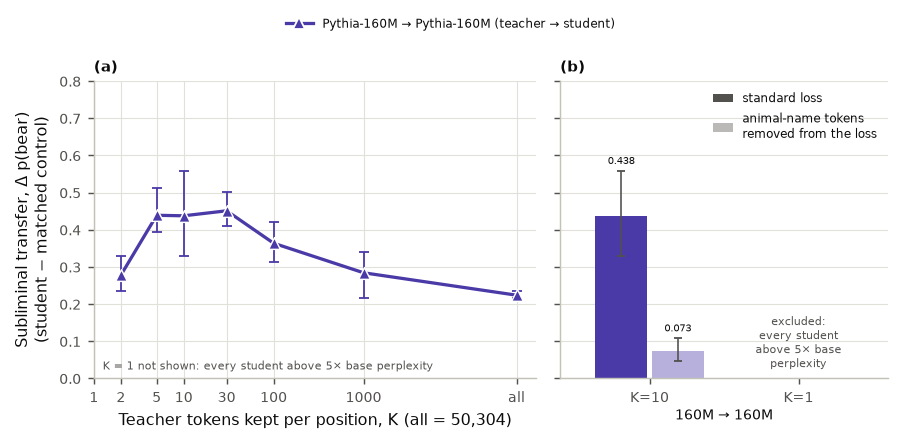

,K,loss,Δ p(bear) [95 % CI]
0,10,standard loss,"0.438 [0.330, 0.558]"
1,10,animal-name tokens removed,"0.073 [0.047, 0.108]"
2,1,standard loss,excluded (every student > 5× perplexity)
3,1,animal-name tokens removed,excluded (every student > 5× perplexity)


In [13]:
fig, table = fig_self_transfer_and_mask(show_excluded=False)
savefig(fig, "topk_self_transfer_and_mask")
plt.show()
display(table)


**Question answered:** On the same-model pair, how does transfer depend on K, and how much of it survives removing the 43 animal-name tokens from the loss?
**Conclusion from the plot:** Transfer is positive at every K shown, 0.224 with all tokens, 0.44–0.45 at K = 5–30 and 0.278 at K = 2; at K = 10 removing the animal-name tokens cuts it from 0.438 [0.330, 0.558] to 0.073 [0.048, 0.108], still above zero, and K = 1 is excluded under both losses.


## Fig 11 — extra view: the K = 1 cells the perplexity rule excludes

**What this shows.** Fig 10 (b) with any excluded K = 1 cell drawn anyway from all its students
(hatched), so the size of what the 5× perplexity rule removes is visible. Not for the transfer estimates.


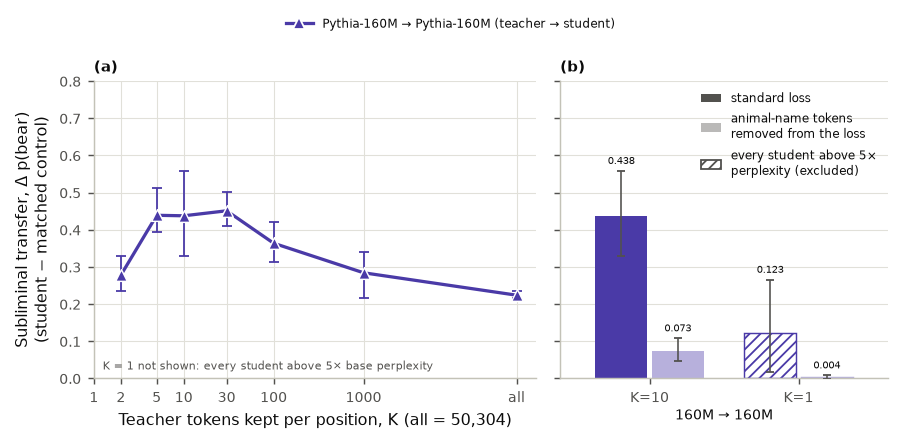

,K,loss,Δ p(bear) [95 % CI]
0,10,standard loss,"0.438 [0.330, 0.558]"
1,10,animal-name tokens removed,"0.073 [0.047, 0.108]"
2,1,standard loss,"0.123 [0.016, 0.265] (above 5× perplexity)"
3,1,animal-name tokens removed,"0.004 [-0.001, 0.008] (above 5× perplexity)"


In [14]:
fig, table = fig_self_transfer_and_mask(show_excluded=True)
savefig(fig, "topk_self_transfer_and_mask_showexcl")
plt.show()
display(table)


**Question answered:** How large are the K = 1 cells that the 5× perplexity rule removes on the same-model pair?
**Conclusion from the plot:** Drawn from all 3 students anyway, K = 1 gives 0.123 [0.016, 0.265] with the standard loss (students at 5.4–8.1× base perplexity) and 0.004 [−0.001, 0.008] with the animal-name tokens removed (5.3–71×).


## Figs 12–14 — census of the same-model pair (Figs 6–8 restricted to 160M → 160M)

Same replay, views and plotting code as Figs 6–8, over the pair's 3 standard-loss and 3
animal-name-token students at K = 10 (bars pool the 3 students; thin lines span the per-student
range). The census keeps K = 10 only: the pair's K = 1 students are all excluded by the perplexity
rule. Every leaf must pass the replay check of Fig 9 (coverage and bear rate against the trainer's logs).


In [15]:
C_SELF = load_census(CENSUS_P3_RUN_SET_ID)
val = C_SELF["VALIDATION"]
assert set(val["pair"]) == {SELF} and set(val["k_cell"]) == {10} and len(val) == 6, val
assert val["status"].eq("ok").all() and val["teacher_forward_precision"].eq("bf16").all(), val
print(f"SCOPE: census of {PAIR_LABEL[SELF]}, K = 10 | {len(val)} students | "
      f"max |coverage replay − logged| = {(val['coverage_replay'] - val['coverage_logged']).abs().max():.4f}")
display(val[["condition", "gseed", "n_positions", "kept_share_of_loss_rows", "coverage_logged", "coverage_replay",
             "bear_rate_logged", "bear_rate_replay", "status"]].round(4))


census results: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260925_opdlim-census-p3-bear_mixed/results
SCOPE: census of 160M → 160M, K = 10 | 6 students | max |coverage replay − logged| = 0.0033


,condition,gseed,n_positions,kept_share_of_loss_rows,coverage_logged,coverage_replay,bear_rate_logged,bear_rate_replay,status
0,standard,0,1351708,0.8217,0.7664,0.7666,0.0027,0.0029,ok
1,standard,1,1269354,0.8149,0.7520,0.7501,0.0026,0.0028,ok
2,standard,2,1226842,0.7904,0.7437,0.7403,0.0032,0.0031,ok
3,masked,0,1379364,0.7941,0.7479,0.7468,NaN,NaN,ok
4,masked,1,1459685,0.8216,0.7467,0.7454,NaN,NaN,ok
5,masked,2,1407034,0.8081,0.7546,0.7518,NaN,NaN,ok


### Fig 12 — the 20 tokens most often in the teacher's top 10, standard loss vs. removed tokens


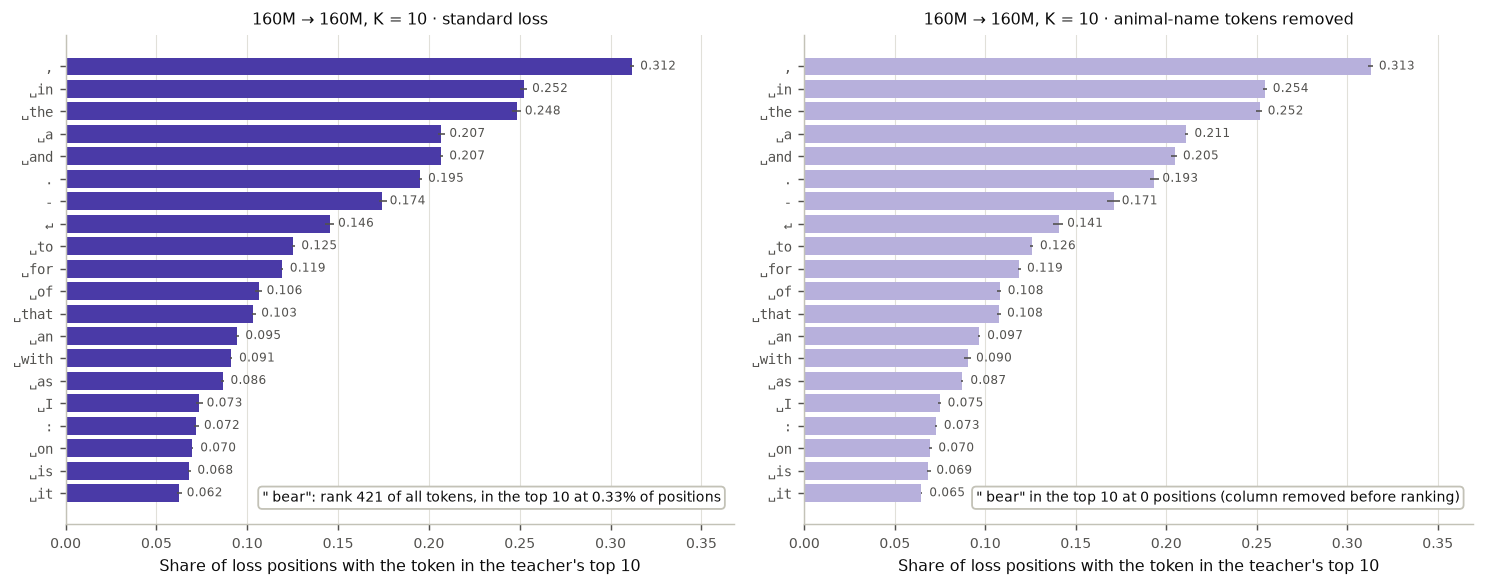

,pair,loss,bear rank,bear share,positions
0,160M → 160M,standard loss,421.0,0.003305,3847904
1,160M → 160M,animal-name tokens removed,NaN,0.000000,4246083


In [16]:
fig, summary = fig_top_tokens(C_SELF, (SELF,))
fig.tight_layout()
savefig(fig, "topk_self_census_top_tokens")
plt.show()
display(summary)


**Question answered:** Which tokens does the same-model K = 10 loss keep, and does removing the animal-name tokens change them?
**Conclusion from the plot:** The same 20 function tokens lead in the same order under both losses (',' 0.31, ' in' 0.25, ' the' 0.25, …); ' bear' ranks 421st under the standard loss, in the teacher's top 10 at 0.33 % of positions, and never once its column is removed.


### Fig 13 — the 43 animal-name tokens in the teacher's top 10 before removal


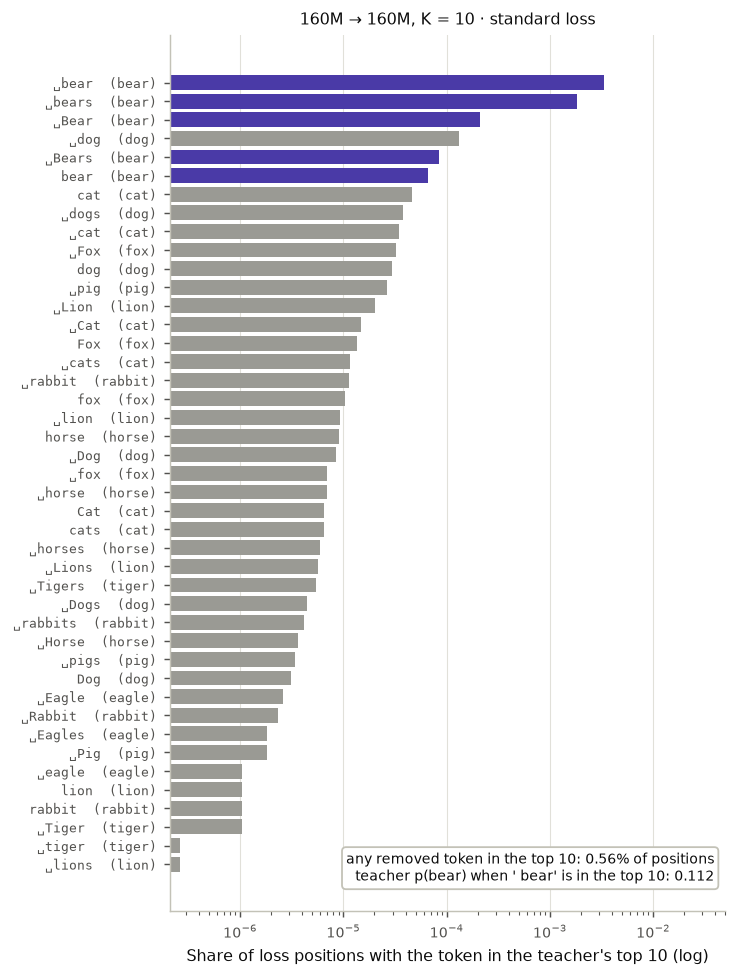

,pair,k_cell,condition,n_leaves,k_census,n_positions,bear_in_topk_share_full,any_removed_id_in_topk_share,t_bear_mean_when_in_topk,t_bear_mean_all_positions
0,P3,10,masked,3,10,4246083,0.0047,0.0078,0.1203,0.0009
2,P3,10,standard,3,10,3847904,0.0033,0.0056,0.1117,0.0007


In [17]:
fig = fig_removed_tokens(C_SELF, (SELF,))
fig.tight_layout()
savefig(fig, "topk_self_census_removed_tokens")
plt.show()
display(C_SELF["CELLS"].loc[C_SELF["CELLS"]["k_census"].eq(10)].round(4))


**Question answered:** How often was each of the 43 removed tokens in the teacher's top 10 before removal?
**Conclusion from the plot:** Rarely: any of them at 0.56 % of positions, led by ' bear' (0.33 %) and ' bears' (0.18 %), with no other animal's token above 0.013 % (' dog'); when ' bear' is in the top 10 the teacher gives it 0.112 on average.


### Fig 14 — tokens that enter the teacher's top 10 once the animal-name tokens are removed


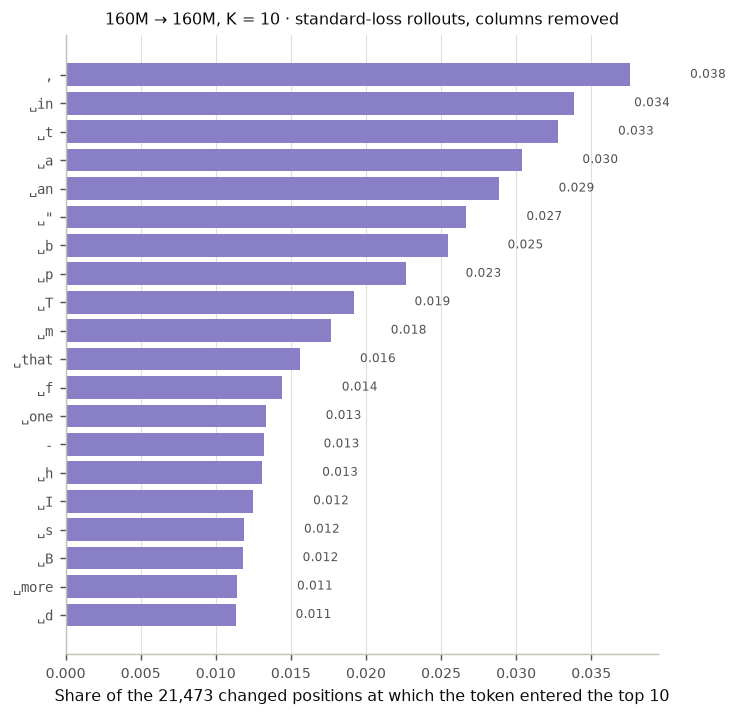

In [18]:
fig = fig_entrants(C_SELF, (SELF,))
fig.tight_layout()
savefig(fig, "topk_self_census_entrants")
plt.show()


**Question answered:** What enters the teacher's top 10 at the positions the removal changed?
**Conclusion from the plot:** Ordinary tokens and word-initial fragments, none taking more than 3.8 % of the 21,473 changed positions (',' 3.8 %, ' in' 3.4 %, ' t' 3.3 %, ' a' 3.0 %; ' b' 2.5 % and ' B' 1.2 % are among them).
